<div class="hero-panel">

# CREDIT PRE-SCREENING ENGINE
### Loan Intake Optimisation with Machine Learning

<span class="hero-kicker">CALIBO AI ACADEMY · PHASE 2 · MINI USE CASE 02</span>

<span class="hero-subtitle">Path 2 · KLU</span>

*A practical, careful look at loan decisions, safe pre-screening, workload and fairness.*
<div class="hero-badges"><span>12,000 applications</span><span>90% policy threshold</span><span>Human review safeguard</span></div>

</div>

<style>
:root { --ink: #102a43; --line: #d9e2ec; --soft: #f4f7fb; --accent: #5c2a9d; }
.jp-Notebook .jp-Cell { max-width: 1180px; margin-left: auto; margin-right: auto; }
.jp-Notebook .jp-RenderedHTMLCommon { color: var(--ink); font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif; line-height: 1.65; }
.jp-Notebook .jp-RenderedHTMLCommon h1 { color: var(--ink); letter-spacing: -0.02em; margin-top: 0.35em; }
.jp-Notebook .jp-RenderedHTMLCommon h2 { color: var(--ink); border-bottom: 2px solid var(--line); padding-bottom: 0.25em; margin-top: 1.7em; }
.jp-Notebook .jp-RenderedHTMLCommon h3 { color: var(--accent); }
.jp-Notebook .jp-MarkdownOutput table { width: 100%; display: block; overflow-x: auto; border: 1px solid var(--line); border-radius: 10px; border-spacing: 0; box-shadow: 0 3px 12px rgba(16, 42, 67, 0.06); }
.jp-Notebook .jp-MarkdownOutput th { background: #102a43; color: white; font-weight: 650; }
.jp-Notebook .jp-MarkdownOutput th, .jp-Notebook .jp-MarkdownOutput td { padding: 10px 13px; border-bottom: 1px solid var(--line); }
.jp-Notebook .jp-MarkdownOutput tr:last-child td { border-bottom: 0; }
.jp-Notebook .jp-MarkdownOutput tr:nth-child(even) td { background: var(--soft); }
.jp-Notebook .jp-RenderedHTMLCommon img { max-width: 100%; height: auto; border-radius: 10px; }
.hero-panel { background: linear-gradient(135deg, #102a43 0%, #243b53 62%, #5c2a9d 100%); color: white; padding: 34px 30px 28px; border-radius: 16px; box-shadow: 0 10px 28px rgba(16, 42, 67, 0.22); text-align: center; }
.hero-panel h1, .hero-panel h3 { color: white !important; border: 0 !important; }
.hero-panel h1 { font-size: 2.45em; margin: 0.25em 0 0.05em; }
.hero-panel h3 { margin: 0; font-weight: 500; opacity: 0.92; }
.hero-kicker { font-size: 0.78em; letter-spacing: 0.14em; font-weight: 700; opacity: 0.82; }
.hero-subtitle { font-size: 0.92em; opacity: 0.82; }
.hero-badges { display: flex; flex-wrap: wrap; gap: 9px; justify-content: center; margin-top: 22px; }
.hero-badges span { padding: 6px 12px; border: 1px solid rgba(255,255,255,0.35); border-radius: 999px; background: rgba(255,255,255,0.12); font-size: 0.82em; }
.notebook-credit { padding: 10px 14px; border-left: 4px solid var(--accent); background: linear-gradient(90deg, #f4f0fb, #faf9fd); border-radius: 7px; color: var(--ink); }
@media (max-width: 700px) { .hero-panel { padding: 25px 18px; } .hero-panel h1 { font-size: 1.85em; } .jp-Notebook .jp-MarkdownOutput th, .jp-Notebook .jp-MarkdownOutput td { padding: 8px; } }
</style>

---

## 1. Business Problem

The bank receives about 3,000 personal-loan applications each month. Each review takes about 25 minutes. This project tests whether Logistic Regression can identify clear historical declines for a careful pre-screening process, while keeping wrongly declined approved applicants at **5% or less**.

**Important:** The model learns past credit-team decisions. It does not prove whether a customer will repay. The data is simulated and used for learning only.

## What this notebook covers

1. Check and clean the data.
2. Find the main patterns behind past approvals.
3. Create affordability features and train Logistic Regression.
4. Measure model performance and explain the errors.
5. Choose a safe auto-decline threshold.
6. Check outcomes by gender.
7. Give a clear policy recommendation.

### How to read the results

| Look for | What it tells you |
|---|---|
| **Tables** | The exact counts, rates and model results. |
| **Dark charts** | The main comparison or pattern in each section. |
| **Takeaways** | The plain-English meaning of the evidence. |
| **Policy briefing** | The final recommendation, safeguard and limitations. |

## 2. CBIM Problem Canvas

| Element | Answer |
|---|---|
| **Situation** | A retail bank manually reviews personal-loan applications from salaried, self-employed, business-owner and gig/contract applicants. |
| **Complication** | Reviews take time. Automating a decline could also turn away a suitable customer. |
| **Question** | Can past decisions support a cautious pre-screener that sends only clear declines away from manual review? |
| **SSOT** | The supplied simulated CSV is the single source of truth. `decision` is the past credit-team decision, not repayment performance. |
| **Success definition** | Find a tested threshold where no more than 5% of auto-declined applications were historically approved, then estimate monthly time saved. |
| **Primary stakeholder** | The Credit Policy Analyst. Lending leaders, analysts and applicants are also affected. |

## 3. Notebook Setup

Keep the CSV in the same folder as this notebook. Restart the kernel and run the cells from top to bottom.

### Team contributions

| Team member | Main contribution | Notebook evidence |
|---|---|---|
| **Pavitra** | Data quality and threshold impact | Steps 5.1 and 5.5 |
| **Rachna** | Approval patterns and fairness | Steps 5.2 and 5.6 |
| **Pratyush** | Affordability features and policy story | Steps 5.3 and 5.7 |
| **Pratik** | Logistic Regression and peer execution check | Step 5.4 and validation record |

**Peer check:** Pratik ran the finished notebook from a clean kernel. Pavitra, Rachna and Pratyush each reviewed a section written by another member. The notebook ran from start to finish with no errors.

**Submission note:** This notebook records four contributors. Please confirm that this team arrangement is accepted by the trainer before submission.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, roc_auc_score,
    confusion_matrix, classification_report
)

warnings.filterwarnings("ignore", category=FutureWarning)
CHART_PALETTE = ["#102a43", "#243b53", "#334e68", "#5c2a9d", "#7b2d26"]
CHART_CMAP = "Blues"
CHART_APPROVAL = "#243b53"
CHART_APPROVAL_DARK = "#102a43"
CHART_ACCENT = "#5c2a9d"
CHART_ALERT = "#7b2d26"
sns.set_theme(style="whitegrid", palette=CHART_PALETTE)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=CHART_PALETTE)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 150,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})


def format_chart(ax, title, xlabel=None, ylabel=None):
    """Apply the shared notebook style to a chart."""
    ax.set_title(title, loc="left", fontweight="bold", pad=12)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    return ax


def add_bar_labels(ax, bars, fmt="{:.1f}%"):
    """Add readable values above bars."""
    for bar in bars:
        value = bar.get_height()
        ax.annotate(
            fmt.format(value),
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 5), textcoords="offset points",
            ha="center", va="bottom", fontsize=9, fontweight="bold"
        )
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Try the standard assignment filename first, then common uploaded variants.
candidates = [
    Path("MUC02_Credit_PreScreening_Dataset.csv"),
    Path("MUC02_Credit_PreScreening_Dataset 1.csv"),
    Path("MUC02_Credit_PreScreening_Dataset 1(3).csv"),
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    csv_files = sorted(Path(".").glob("MUC02_Credit_PreScreening_Dataset*.csv"))
    if not csv_files:
        raise FileNotFoundError(
            "Place MUC02_Credit_PreScreening_Dataset.csv in the notebook folder."
        )
    DATA_PATH = csv_files[0]

df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH.name} | Shape: {df_raw.shape}")

Loaded: MUC02_Credit_PreScreening_Dataset.csv | Shape: (12000, 19)


# Step 5.1 — Load, Inspect and Clean

<div class="notebook-credit"><strong>Built by:</strong> Pavitra</div>

We first check the data shape, column types, missing values and approval balance. We then make a clear decision about missing income, blank credit scores and unusually high income values.

In [2]:
display(df_raw.head())
print("Rows and columns:", df_raw.shape)
display(pd.DataFrame({
    "Data type": df_raw.dtypes.astype(str),
    "Missing values": df_raw.isna().sum(),
    "Missing (%)": (df_raw.isna().mean() * 100).round(2)
}))

,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.100,"95,000.000","23,500.000",784.000,109,2,0,Home Renovation,"240,000.000",48,"6,600.000",Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.600,"43,000.000","8,500.000",790.000,162,2,0,Wedding,"145,000.000",36,"5,000.000",Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.400,"35,000.000","3,500.000",718.000,151,1,1,Medical,"345,000.000",36,"11,800.000",Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.800,"44,500.000",0.000,NaN,0,0,0,Travel,"135,000.000",36,"4,600.000",Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.100,"83,500.000","6,000.000",700.000,127,1,3,Medical,"700,000.000",24,"33,600.000",Declined


Rows and columns: (12000, 19)


,Data type,Missing values,Missing (%)
application_id,str,0,0.000
application_date,str,0,0.000
age,int64,0,0.000
gender,str,0,0.000
city,str,0,0.000
city_tier,int64,0,0.000
employment_type,str,0,0.000
years_in_current_job,float64,0,0.000
monthly_income,float64,441,3.680
existing_emi,float64,0,0.000


In [3]:
decision_counts = df_raw["decision"].value_counts()
approval_rate = df_raw["decision"].eq("Approved").mean() * 100

display(decision_counts.rename("Applications").to_frame())
print(f"Historical approval rate: {approval_rate:.2f}%")

,Applications
decision,
Approved,6353
Declined,5647


Historical approval rate: 52.94%


### 5.1.1 Missing monthly income

We check which employment groups have missing income. For descriptive analysis, we use the median income within each employment group. The model learns its imputation values from the training data only, which avoids leakage.

In [4]:
income_missing = (
    df_raw.assign(income_missing=df_raw["monthly_income"].isna())
    .groupby("employment_type")
    .agg(
        Applications=("application_id", "size"),
        Missing_Income=("income_missing", "sum"),
        Median_Reported_Income=("monthly_income", "median")
    )
)
income_missing["Missing (%)"] = (
    income_missing["Missing_Income"] / income_missing["Applications"] * 100
)
display(income_missing.style.format({
    "Applications": "{:,.0f}", "Missing_Income": "{:,.0f}",
    "Median_Reported_Income": "₹{:,.0f}", "Missing (%)": "{:.2f}%"
}))
print("Total missing income values:", int(df_raw["monthly_income"].isna().sum()))

,Applications,Missing_Income,Median_Reported_Income,Missing (%)
employment_type,,,,
Business Owner,"1,749",227,"₹69,500",12.98%
Gig / Contract,"1,766",11,"₹28,000",0.62%
Salaried,"7,057",49,"₹50,000",0.69%
Self-Employed Professional,"1,428",154,"₹75,000",10.78%


Total missing income values: 441


**Cleaning decision:** There are 441 missing incomes, mainly among self-employed professionals and business owners. Group medians are a simple and explainable way to fill them. We also keep the missing-income pattern documented because it may reflect how income was collected.

### 5.1.2 Missing credit scores

Blank scores are checked against credit-history length. We keep these applicants and create `is_ntc` to identify new-to-credit applicants.

In [5]:
missing_score = df_raw["credit_score"].isna()
ntc_check = df_raw.loc[missing_score, "credit_history_months"].value_counts(dropna=False)
print("Applications without a score:", int(missing_score.sum()))
print("Credit history months among applicants without a score:")
display(ntc_check.rename("Applications").to_frame())
print("Share of all applications:", f"{missing_score.mean() * 100:.2f}%")

Applications without a score: 1039
Credit history months among applicants without a score:


,Applications
credit_history_months,
0,1039


Share of all applications: 8.66%


**Cleaning decision:** All 1,039 blank scores have zero months of credit history, so they represent new-to-credit applicants rather than bad data. We keep them and use `is_ntc`; dropping them would remove an important group.

### 5.1.3 Unusually high monthly incomes

Twelve income values are above ₹6 lakh per month, and all are for salaried applicants. They are most likely annual salaries entered as monthly income, so we divide those values by 12 and record the assumption.

In [6]:
high_income_mask = df_raw["monthly_income"] > 600_000
high_income_rows = df_raw.loc[
    high_income_mask, ["application_id", "employment_type", "monthly_income"]
]
display(high_income_rows)
print("Values above ₹6,00,000:", int(high_income_mask.sum()))
print("Employment types among these values:")
display(df_raw.loc[high_income_mask, "employment_type"].value_counts().to_frame("Count"))

,application_id,employment_type,monthly_income
300,APP100301,Salaried,"1,254,000.000"
589,APP100590,Salaried,"1,068,000.000"
1467,APP101468,Salaried,"1,656,000.000"
1848,APP101849,Salaried,"984,000.000"
2488,APP102489,Salaried,"972,000.000"
2493,APP102494,Salaried,"1,212,000.000"
4010,APP104011,Salaried,"900,000.000"
4898,APP104899,Salaried,"870,000.000"
7426,APP107427,Salaried,"690,000.000"
8381,APP108382,Salaried,"618,000.000"


Values above ₹6,00,000: 12
Employment types among these values:


,Count
employment_type,
Salaried,12


### 5.1.4 Create the analysis copy

The raw data stays unchanged. The analysis copy corrects the 12 likely annual-income entries, flags new-to-credit applicants and fills missing incomes for descriptive work. The model has its own training-only preprocessing.

In [7]:
df_analysis = df_raw.copy()
df_analysis["application_date"] = pd.to_datetime(
    df_analysis["application_date"], errors="coerce"
)
df_analysis.loc[high_income_mask, "monthly_income"] /= 12
df_analysis["is_ntc"] = (
    df_analysis["credit_score"].isna()
    & df_analysis["credit_history_months"].eq(0)
).astype(int)

income_medians_all = df_analysis.groupby("employment_type")["monthly_income"].median()
df_analysis["monthly_income"] = df_analysis["monthly_income"].fillna(
    df_analysis["employment_type"].map(income_medians_all)
)
df_analysis["monthly_income"] = df_analysis["monthly_income"].fillna(
    df_analysis["monthly_income"].median()
)
df_analysis["approval_flag"] = df_analysis["decision"].eq("Approved").astype(int)

print("Analysis dataset:", df_analysis.shape)
print("Missing income after descriptive cleaning:", int(df_analysis["monthly_income"].isna().sum()))
print("New to credit applicants:", int(df_analysis["is_ntc"].sum()))

Analysis dataset: (12000, 21)
Missing income after descriptive cleaning: 0
New to credit applicants: 1039


**Step 5.1 takeaway:** We found 441 missing incomes, 1,039 blank credit scores and 12 likely annual-income entries. We kept new-to-credit applicants, documented every assumption and left the original CSV untouched.

# Step 5.2 — What Drives Approval Today?

<div class="notebook-credit"><strong>Built by:</strong> Rachna</div>

Before building the model, we look at how the credit team made past decisions. We compare credit-score bands, the “No score” group and employment types.

The historical score pattern is strong: approval is **2.0% below 600**, **3.2% for 600–649**, and **53.9% for applicants without a score**. This means low scores are linked to very low past approval, but a missing score should not be treated as a decline signal because many new-to-credit applicants were approved.

In [8]:
score_bins = [-np.inf, 600, 650, 700, 750, 800, np.inf]
score_labels = ["Below 600", "600–649", "650–699", "700–749", "750–799", "800+"]

df_analysis["credit_score_band"] = pd.cut(
    df_analysis["credit_score"], bins=score_bins, labels=score_labels,
    right=False
).astype("object")
df_analysis.loc[df_analysis["is_ntc"].eq(1), "credit_score_band"] = "No score"

score_order = score_labels + ["No score"]
score_summary = (
    df_analysis.groupby("credit_score_band", observed=False)
    .agg(Applications=("decision", "size"), Approval_Rate=("approval_flag", "mean"))
    .reindex(score_order)
)
score_summary["Approval Rate (%)"] = score_summary.pop("Approval_Rate") * 100
display(score_summary.style.format({
    "Applications": "{:,.0f}", "Approval Rate (%)": "{:.1f}%"
}))

,Applications,Approval Rate (%)
credit_score_band,,
Below 600,246,2.0%
600–649,933,3.2%
650–699,"2,529",32.5%
700–749,"3,377",54.4%
750–799,"2,526",77.2%
800+,"1,350",85.2%
No score,"1,039",53.9%


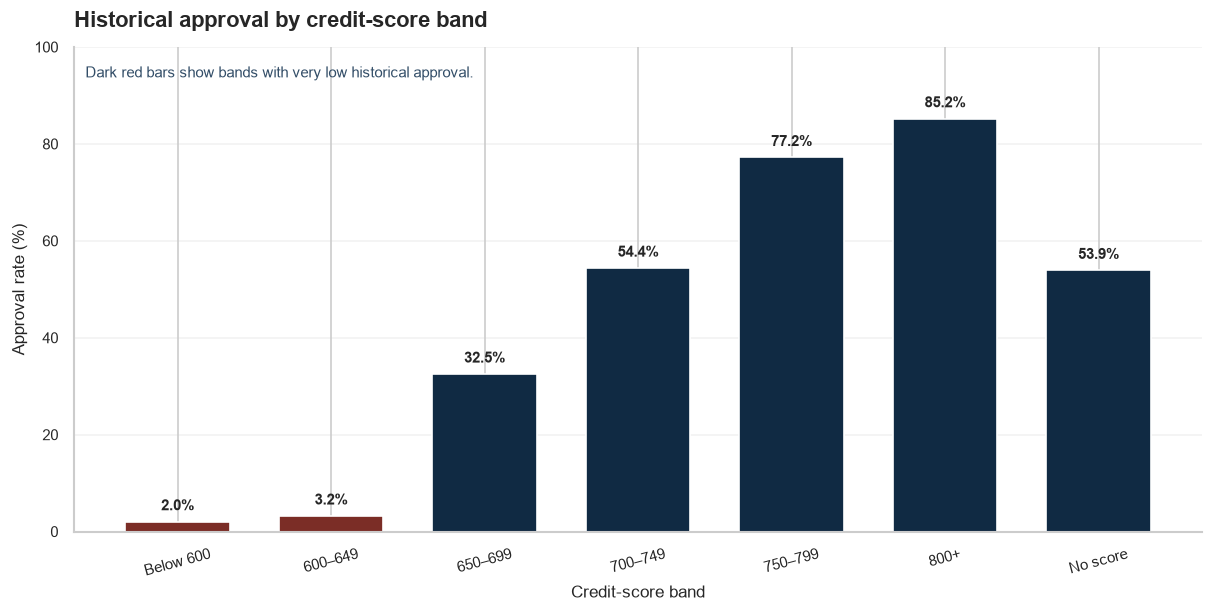

In [9]:
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
colors = [CHART_ALERT if value < 10 else CHART_APPROVAL_DARK for value in score_summary["Approval Rate (%)"]]
bars = ax.bar(score_summary.index, score_summary["Approval Rate (%)"], color=colors, width=0.68)
add_bar_labels(ax, bars)
format_chart(ax, "Historical approval by credit-score band", "Credit-score band", "Approval rate (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=15)
ax.text(0.01, 0.96, "Dark red bars show bands with very low historical approval.", transform=ax.transAxes, fontsize=9, color="#334e68", va="top")
plt.show()

,Applications,Approval Rate (%)
employment_type,,
Business Owner,"1,749",51.2%
Gig / Contract,"1,766",34.9%
Salaried,"7,057",58.4%
Self-Employed Professional,"1,428",50.6%


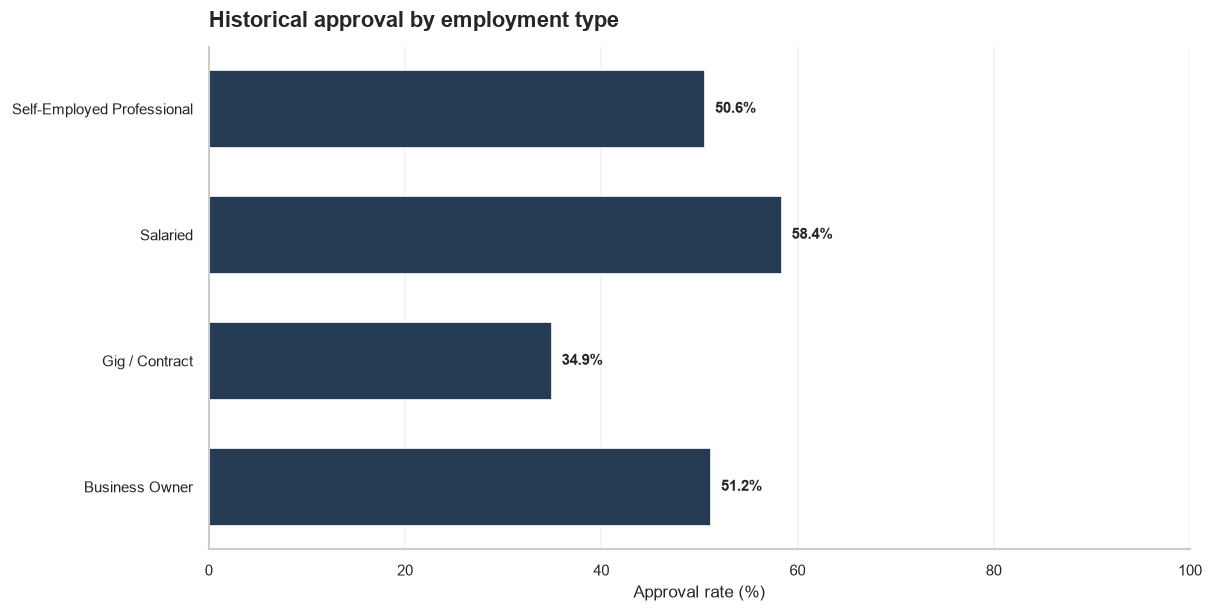

In [10]:
employment_summary = (
    df_analysis.groupby("employment_type")
    .agg(Applications=("decision", "size"), Approval_Rate=("approval_flag", "mean"))
)
employment_summary["Approval Rate (%)"] = employment_summary.pop("Approval_Rate") * 100
display(employment_summary.style.format({
    "Applications": "{:,.0f}", "Approval Rate (%)": "{:.1f}%"
}))

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
bars = ax.barh(
    employment_summary.index,
    employment_summary["Approval Rate (%)"],
    color=CHART_APPROVAL,
    height=0.62,
)
for bar in bars:
    ax.annotate(
        f"{bar.get_width():.1f}%",
        (bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(6, 0), textcoords="offset points",
        va="center", fontsize=9, fontweight="bold"
    )
format_chart(ax, "Historical approval by employment type", "Approval rate (%)", None)
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)
plt.show()

### What this means

Approval is very low below a credit score of 650, while new-to-credit applicants are treated differently. These are patterns in past decisions, not proof that one applicant will repay. Employment mix also matters, especially for Gig / Contract applicants.

# Step 5.3 — Engineer Affordability Features

<div class="notebook-credit"><strong>Built by:</strong> Pratyush</div>

We create three features: `foir`, `loan_to_income` and `is_ntc`. FOIR is the share of monthly income used for existing and proposed EMIs. Loan-to-income compares the requested loan with annual income.

In [11]:
df_features = df_analysis.copy()
df_features["foir"] = (
    (df_features["existing_emi"] + df_features["proposed_emi"])
    / df_features["monthly_income"].replace(0, np.nan)
)
df_features["loan_to_income"] = (
    df_features["loan_amount"]
    / (df_features["monthly_income"].replace(0, np.nan) * 12)
)
df_features["is_ntc"] = (
    df_features["credit_score"].isna()
    & df_features["credit_history_months"].eq(0)
).astype(int)

display(df_features[["foir", "loan_to_income", "is_ntc"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
foir,"12,000.000",0.358,0.207,0.005,0.214,0.317,0.450,3.393
loan_to_income,"12,000.000",0.531,0.225,0.015,0.346,0.519,0.699,2.778
is_ntc,"12,000.000",0.087,0.281,0.000,0.000,0.000,0.000,1.000


,Applications,Approval Rate (%)
foir_band,,
Below 30%,"5,491",65.5%
30–40%,"2,497",59.0%
40–50%,"1,766",47.8%
50–55%,531,32.4%
Above 55%,"1,715",15.6%


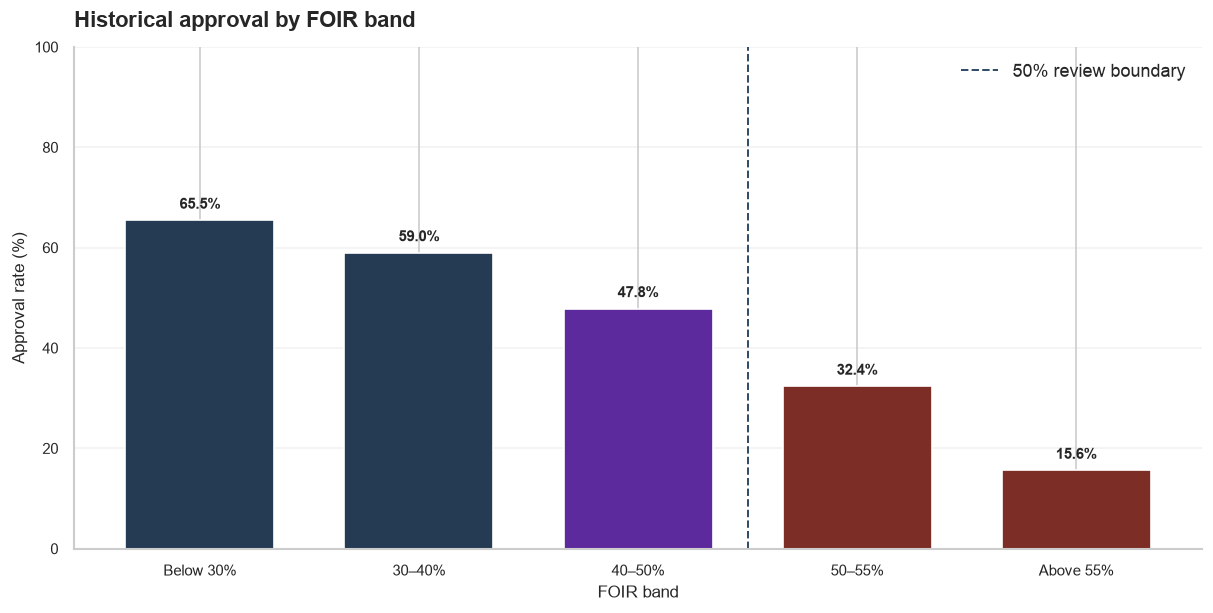

In [12]:
foir_bins = [-np.inf, 0.30, 0.40, 0.50, 0.55, np.inf]
foir_labels = ["Below 30%", "30–40%", "40–50%", "50–55%", "Above 55%"]
df_features["foir_band"] = pd.cut(
    df_features["foir"], bins=foir_bins, labels=foir_labels, right=False
)
foir_summary = (
    df_features.groupby("foir_band", observed=False)
    .agg(Applications=("decision", "size"), Approval_Rate=("approval_flag", "mean"))
    .reindex(foir_labels)
)
foir_summary["Approval Rate (%)"] = foir_summary.pop("Approval_Rate") * 100
display(foir_summary.style.format({
    "Applications": "{:,.0f}", "Approval Rate (%)": "{:.1f}%"
}))

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
colors = [CHART_APPROVAL, CHART_APPROVAL, CHART_ACCENT, CHART_ALERT, CHART_ALERT]
bars = ax.bar(foir_summary.index, foir_summary["Approval Rate (%)"], color=colors, width=0.68)
add_bar_labels(ax, bars)
format_chart(ax, "Historical approval by FOIR band", "FOIR band", "Approval rate (%)")
ax.set_ylim(0, 100)
ax.axvline(2.5, color="#334e68", linestyle="--", linewidth=1.2, label="50% review boundary")
ax.legend(frameon=False, loc="upper right")
plt.show()

### What this means

Approval falls quickly when FOIR moves above 50%. The historical pattern supports a cautious 50–55% review boundary, not an automatic rejection rule. Cases near or above the boundary should still be reviewed by a person.

# Step 5.4 — Build the Logistic Regression Pre-Screener

<div class="notebook-credit"><strong>Built by:</strong> Pratik</div>

The target is `1` for Declined and `0` for Approved. We use only the required features and leave out application ID, date, city, gender and the decision column.

To avoid leakage, we split the data first. Income correction, median filling, feature creation and scaling are learned from the training data only.

In [13]:
# Target and permitted features
numeric_features = [
    "credit_score", "is_ntc", "foir", "loan_to_income",
    "delinquencies_24m", "num_active_loans", "years_in_current_job",
    "age", "tenure_months", "city_tier"
]
categorical_features = ["employment_type", "loan_purpose"]
feature_columns = numeric_features + categorical_features

# Correct the identified annual-income entries before splitting.
model_raw = df_raw.copy()
model_raw.loc[model_raw["monthly_income"] > 600_000, "monthly_income"] /= 12
model_raw["is_ntc"] = (
    model_raw["credit_score"].isna()
    & model_raw["credit_history_months"].eq(0)
).astype(int)
y = model_raw["decision"].eq("Declined").astype(int)

train_idx, test_idx = train_test_split(
    model_raw.index, test_size=0.20, random_state=42, stratify=y
)
train_raw = model_raw.loc[train_idx].copy()
test_raw = model_raw.loc[test_idx].copy()
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

# Learn income medians from training data only and apply to both sets.
income_medians = train_raw.groupby("employment_type")["monthly_income"].median()
overall_income_median = train_raw["monthly_income"].median()

def prepare_features(frame):
    out = frame.copy()
    out["monthly_income"] = out["monthly_income"].fillna(
        out["employment_type"].map(income_medians)
    ).fillna(overall_income_median)
    out["foir"] = (
        (out["existing_emi"] + out["proposed_emi"])
        / out["monthly_income"].replace(0, np.nan)
    )
    out["loan_to_income"] = (
        out["loan_amount"] / (out["monthly_income"].replace(0, np.nan) * 12)
    )
    return out[feature_columns]

X_train = prepare_features(train_raw)
X_test = prepare_features(test_raw)

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Features:", feature_columns)

Training rows: 9600 | Test rows: 2400
Features: ['credit_score', 'is_ntc', 'foir', 'loan_to_income', 'delinquencies_24m', 'num_active_loans', 'years_in_current_job', 'age', 'tenure_months', 'city_tier', 'employment_type', 'loan_purpose']


### Preprocessing and training

Numeric features are median-imputed and scaled. Employment type and loan purpose are one-hot encoded. All preprocessing sits inside the training pipeline, followed by Logistic Regression.

In [14]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
decline_prob = model.predict_proba(X_test)[:, 1]
metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (Declined)": precision_score(y_test, y_pred, zero_division=0),
    "Recall (Declined)": recall_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, decline_prob)
})
display((metrics * 100).rename("Score (%)").to_frame().style.format("{:.2f}%"))

,Score (%)
Accuracy,79.08%
Precision (Declined),79.16%
Recall (Declined),75.38%
ROC-AUC,86.74%


### Confusion matrix in business terms

The model predicts past analyst decisions, not repayment. A false positive is an applicant who was historically Approved but predicted Declined. At the 0.50 cut-off, 224 such applicants would have been wrongly turned away. This is why the model should support a narrow pre-screening lane, not replace credit review.

,Predicted Approved,Predicted Declined
Actually Approved,1047,224
Actually Declined,278,851


Historically approved applicants predicted Declined at 0.50: 224
              precision    recall  f1-score   support

    Approved       0.79      0.82      0.81      1271
    Declined       0.79      0.75      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.79      0.79      0.79      2400
weighted avg       0.79      0.79      0.79      2400



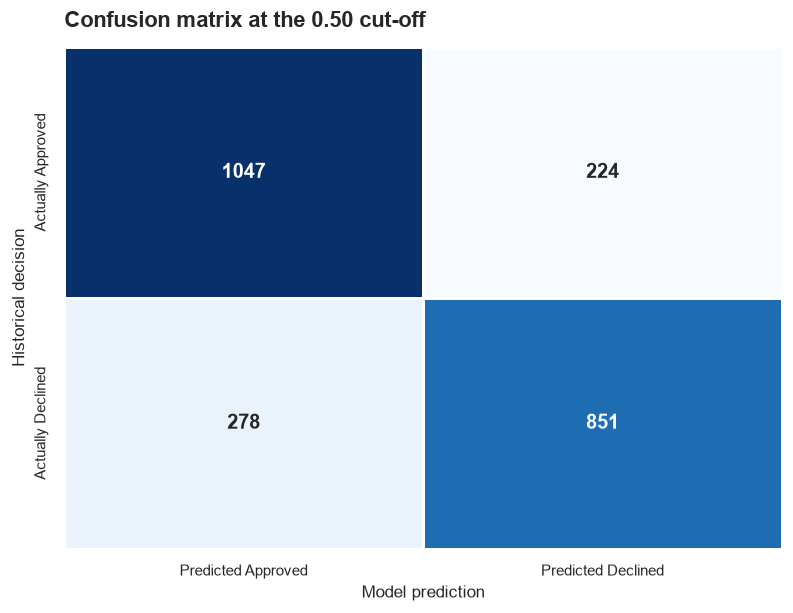

In [15]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_table = pd.DataFrame(
    cm,
    index=["Actually Approved", "Actually Declined"],
    columns=["Predicted Approved", "Predicted Declined"]
)
display(cm_table)
wrong_good_customers = int(cm[0, 1])
print(f"Historically approved applicants predicted Declined at 0.50: {wrong_good_customers}")
print(classification_report(
    y_test, y_pred, labels=[0, 1],
    target_names=["Approved", "Declined"], zero_division=0
))

fig, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)
sns.heatmap(
    cm_table, annot=True, fmt="d", cmap="Blues", linewidths=1.5,
    linecolor="white", cbar=False, ax=ax, annot_kws={"fontsize": 12, "fontweight": "bold"}
)
format_chart(ax, "Confusion matrix at the 0.50 cut-off", None, None)
ax.set_xlabel("Model prediction")
ax.set_ylabel("Historical decision")
plt.show()

### Strongest model coefficients

Positive coefficients push a case towards Declined; negative coefficients push it towards Approved. Because numeric features are scaled, their sizes can be compared. FOIR is the strongest positive signal (**+1.22**), credit score is a strong negative signal (**−1.01**), and delinquencies also push towards decline (**+0.98**).

,Coefficient
numeric__foir,+1.220
numeric__credit_score,-1.010
numeric__delinquencies_24m,+0.979
categorical__employment_type_Gig / Contract,+0.618
categorical__employment_type_Salaried,-0.446


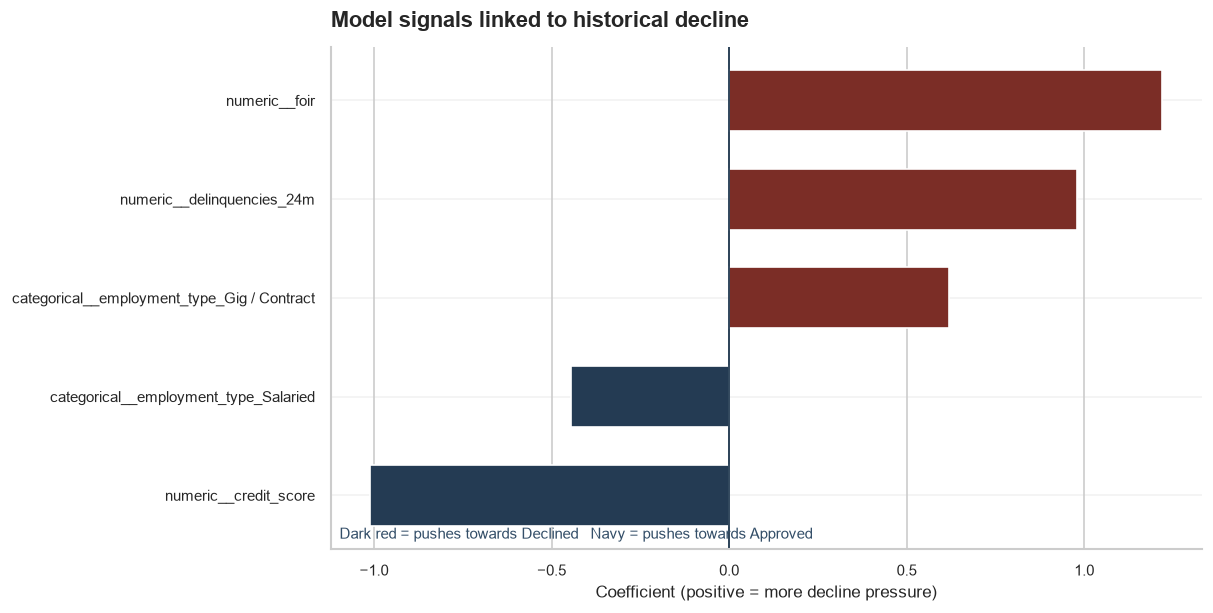

In [16]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = pd.Series(
    model.named_steps["classifier"].coef_[0], index=feature_names
)
top_five_coefficients = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).head(5).index
).sort_values(key=np.abs, ascending=False)

display(top_five_coefficients.rename("Coefficient").to_frame().style.format("{:+.3f}"))

plot_coefs = top_five_coefficients.sort_values()
colors = [CHART_ALERT if value > 0 else CHART_APPROVAL for value in plot_coefs.values]
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.barh(plot_coefs.index, plot_coefs.values, color=colors, height=0.62)
ax.axvline(0, color="#102a43", linewidth=1)
format_chart(ax, "Model signals linked to historical decline", "Coefficient (positive = more decline pressure)", None)
ax.text(0.01, 0.02, "Dark red = pushes towards Declined   Navy = pushes towards Approved", transform=ax.transAxes, fontsize=9, color="#334e68")
plt.show()

### New-to-credit reliability

Overall accuracy can hide weak performance for applicants without a credit score. We compare the held-out accuracy for new-to-credit applicants with the accuracy for applicants who have a score.

In [17]:
test_groups = test_raw[["credit_score", "credit_history_months"]].copy()
test_groups["is_ntc"] = (
    test_groups["credit_score"].isna()
    & test_groups["credit_history_months"].eq(0)
)
test_groups["actual"] = y_test
test_groups["predicted"] = y_pred
subgroup_rows = []
for label, group in test_groups.groupby("is_ntc"):
    subgroup_rows.append({
        "Applicant Group": "New to credit" if label else "Credit score available",
        "Applications": len(group),
        "Accuracy (%)": accuracy_score(group["actual"], group["predicted"]) * 100
    })
subgroup_accuracy = pd.DataFrame(subgroup_rows).set_index("Applicant Group")
display(subgroup_accuracy.style.format({
    "Applications": "{:,.0f}", "Accuracy (%)": "{:.1f}%"
}))

,Applications,Accuracy (%)
Applicant Group,,
Credit score available,"2,197",81.2%
New to credit,203,56.7%


**Step 5.4 takeaway:** Logistic Regression gives a useful probability of historical decline, but accuracy alone is not enough. The five strongest signals are FOIR (**+1.220**, more decline pressure), credit score (**−1.010**, less decline pressure), delinquencies in the last 24 months (**+0.979**, more decline pressure), Gig / Contract employment (**+0.618** versus the reference employment group, more decline pressure) and Salaried employment (**−0.446**, less decline pressure). These are associations with past analyst decisions, not proof of repayment risk. The false-positive count and the weaker new-to-credit result must guide how the model is used.

# Step 5.5 — Set the Auto-Decline Threshold

<div class="notebook-credit"><strong>Built by:</strong> Pavitra</div>

The bank will auto-decline only when no more than 5% of that lane were historically approved. We test all seven required thresholds and choose the lowest one that meets the rule.

The selected threshold is **0.90**. At this level, the policy removes about **456 applications** from manual review each month and saves about **190.1 analyst hours**, while keeping historically approved applicants in the auto-decline lane to about **4.7%**.

In [18]:
thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]
threshold_rows = []

for threshold in thresholds:
    auto_decline = decline_prob >= threshold
    count = int(auto_decline.sum())
    wrong_count = int(((y_test.to_numpy() == 0) & auto_decline).sum())
    threshold_rows.append({
        "Threshold": threshold,
        "Auto Declined": count,
        "Auto Declined (%)": count / len(y_test) * 100,
        "Wrongly Declined": wrong_count,
        "Wrongly Declined (%)": (
            wrong_count / count * 100 if count else np.nan
        )
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.style.format({
    "Threshold": "{:.2f}", "Auto Declined": "{:,.0f}",
    "Auto Declined (%)": "{:.1f}%", "Wrongly Declined": "{:,.0f}",
    "Wrongly Declined (%)": "{:.1f}%"
}))

,Threshold,Auto Declined,Auto Declined (%),Wrongly Declined,Wrongly Declined (%)
0,0.50,"1,075",44.8%,224,20.8%
1,0.60,902,37.6%,152,16.9%
2,0.70,738,30.8%,89,12.1%
3,0.80,564,23.5%,39,6.9%
4,0.85,472,19.7%,28,5.9%
5,0.90,365,15.2%,17,4.7%
6,0.95,241,10.0%,5,2.1%


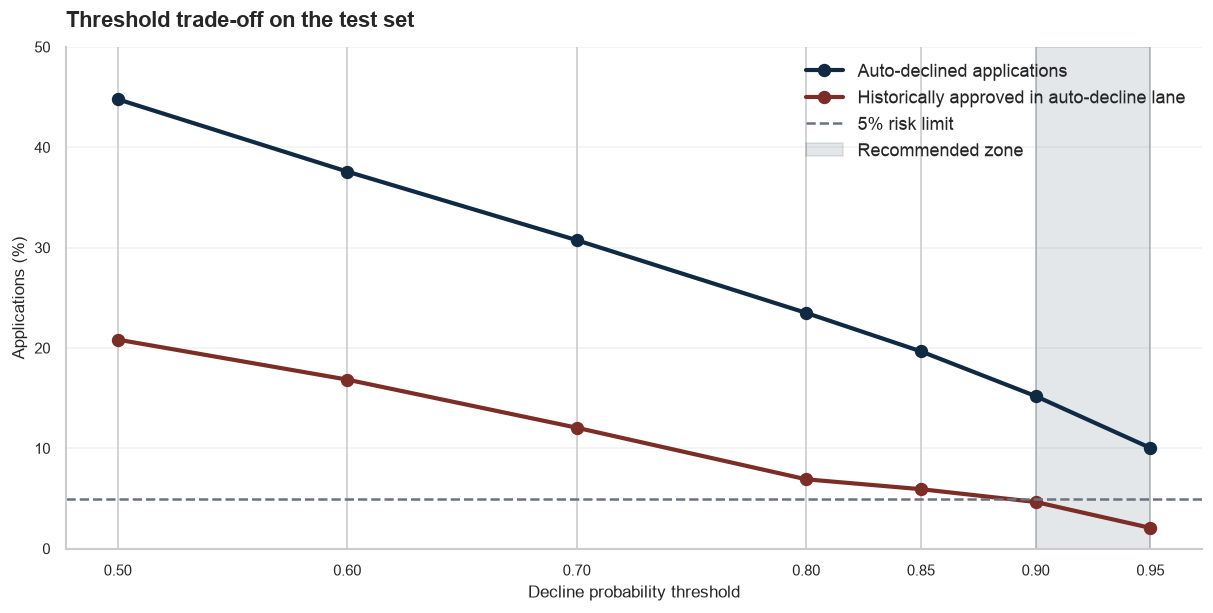

In [19]:
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.plot(
    threshold_table["Threshold"], threshold_table["Auto Declined (%)"],
    marker="o", markersize=7, linewidth=2.5, color=CHART_APPROVAL_DARK,
    label="Auto-declined applications"
)
ax.plot(
    threshold_table["Threshold"], threshold_table["Wrongly Declined (%)"],
    marker="o", markersize=7, linewidth=2.5, color=CHART_ALERT,
    label="Historically approved in auto-decline lane"
)
ax.axhline(5, color="#6b7280", linestyle="--", linewidth=1.5, label="5% risk limit")
ax.axvspan(0.90, 0.95, color=CHART_APPROVAL, alpha=0.12, label="Recommended zone")
format_chart(ax, "Threshold trade-off on the test set", "Decline probability threshold", "Applications (%)")
ax.set_xticks(thresholds)
ax.set_ylim(0, 50)
ax.legend(frameon=False, loc="upper right")
plt.show()

### Select the threshold and estimate the business impact

We choose the lowest threshold where wrongly declined approved applicants are at or below 5%. The monthly estimate uses 3,000 applications and 25 minutes per manual review.

**Recommendation:** A threshold of **0.90** meets the rule. It covers **15.2%** of the test set, with **4.7%** historically approved in that lane. This equals about **456 applications** and **190.1 analyst hours** saved per month. Keeping new-to-credit applicants with analysts gives a safer estimate of about **441 applications** and **183.9 hours**.

In [20]:
eligible = threshold_table[
    threshold_table["Wrongly Declined (%)"].notna()
    & (threshold_table["Wrongly Declined (%)"] <= 5)
]
chosen_threshold = (
    float(eligible.iloc[0]["Threshold"]) if not eligible.empty else None
)

monthly_applications = 3_000
review_minutes = 25

if chosen_threshold is None:
    print("No tested threshold meets the 5% rule. Do not recommend auto decline.")
    monthly_auto = monthly_hours = np.nan
else:
    selected = threshold_table.loc[
        threshold_table["Threshold"].eq(chosen_threshold)
    ].iloc[0]
    monthly_auto = monthly_applications * selected["Auto Declined (%)"] / 100
    monthly_hours = monthly_auto * review_minutes / 60
    print(f"Recommended threshold: {chosen_threshold:.2f}")
    print(f"Test auto decline rate: {selected['Auto Declined (%)']:.2f}%")
    print(f"Wrongly declined among auto declines: {selected['Wrongly Declined (%)']:.2f}%")
    print(f"Estimated monthly applications routed out of review: {monthly_auto:.0f}")
    print(f"Estimated gross analyst hours freed: {monthly_hours:.1f}")

Recommended threshold: 0.90
Test auto decline rate: 15.21%
Wrongly declined among auto declines: 4.66%
Estimated monthly applications routed out of review: 456
Estimated gross analyst hours freed: 190.1


### Keep new-to-credit applicants with analysts

New-to-credit applicants are harder for the model to classify, so they stay in the human-review queue. The next calculation shows the safer impact after this safeguard.

In [21]:
if chosen_threshold is not None:
    test_ntc = (
        test_raw["credit_score"].isna()
        & test_raw["credit_history_months"].eq(0)
    ).to_numpy()
    auto_mask = decline_prob >= chosen_threshold
    eligible_auto = auto_mask & ~test_ntc
    wrong_eligible = eligible_auto & (y_test.to_numpy() == 0)
    eligible_count = int(eligible_auto.sum())
    eligible_wrong_rate = (
        wrong_eligible.sum() / eligible_count * 100 if eligible_count else np.nan
    )
    adjusted_monthly_auto = monthly_applications * eligible_count / len(y_test)
    adjusted_monthly_hours = adjusted_monthly_auto * review_minutes / 60

    display(pd.DataFrame({
        "Measure": [
            "Test applications auto declined after NTC safeguard",
            "Wrongful decline rate among eligible auto declines",
            "Estimated monthly applications routed out of review",
            "Estimated monthly analyst hours freed"
        ],
        "Result": [
            f"{eligible_count:,}",
            f"{eligible_wrong_rate:.2f}%" if pd.notna(eligible_wrong_rate) else "N/A",
            f"{adjusted_monthly_auto:.0f}",
            f"{adjusted_monthly_hours:.1f}"
        ]
    }))

,Measure,Result
0,Test applications auto declined after NTC safe...,353
1,Wrongful decline rate among eligible auto decl...,3.12%
2,Estimated monthly applications routed out of r...,441
3,Estimated monthly analyst hours freed,183.9


**What this means:** The gross estimate is useful for planning, but the safeguarded estimate is the better first-pilot number. Both estimates assume the test set represents future applications.

# Step 5.6 — Fairness Check

<div class="notebook-credit"><strong>Built by:</strong> Rachna</div>

Gender is not used as a model feature, but that alone does not prove fairness. We compare approval rates, income, employment mix and auto-decline rates by gender.

The safeguarded model leaves the observed gender auto-decline gap nearly unchanged: **15.60% for Female applicants versus 15.03% for Male applicants**. Excluding gender does not remove indirect effects because income, employment type, credit history and affordability can differ across groups and can act as proxy features. The result should therefore be monitored by gender and employment type each month.

In [22]:
gender_summary = (
    df_analysis.groupby("gender", dropna=False)
    .agg(
        Applications=("application_id", "size"),
        Approved=("approval_flag", "sum"),
        Approval_Rate=("approval_flag", "mean"),
        Median_Monthly_Income=("monthly_income", "median"),
        Gig_Contract_Share=("employment_type",
            lambda s: s.eq("Gig / Contract").mean())
    )
)
gender_summary["Approval_Rate"] *= 100
gender_summary["Gig_Contract_Share"] *= 100
display(gender_summary.style.format({
    "Applications": "{:,.0f}", "Approved": "{:,.0f}",
    "Approval_Rate": "{:.1f}%", "Median_Monthly_Income": "₹{:,.0f}",
    "Gig_Contract_Share": "{:.1f}%"
}))

,Applications,Approved,Approval_Rate,Median_Monthly_Income,Gig_Contract_Share
gender,,,,,
Female,"3,795","1,914",50.4%,"₹45,000",21.4%
Male,"8,205","4,439",54.1%,"₹55,000",11.6%


gender,Female,Male
employment_type,,
Business Owner,51.6%,51.1%
Gig / Contract,34.6%,35.2%
Salaried,56.8%,59.1%
Self-Employed Professional,47.6%,52.0%


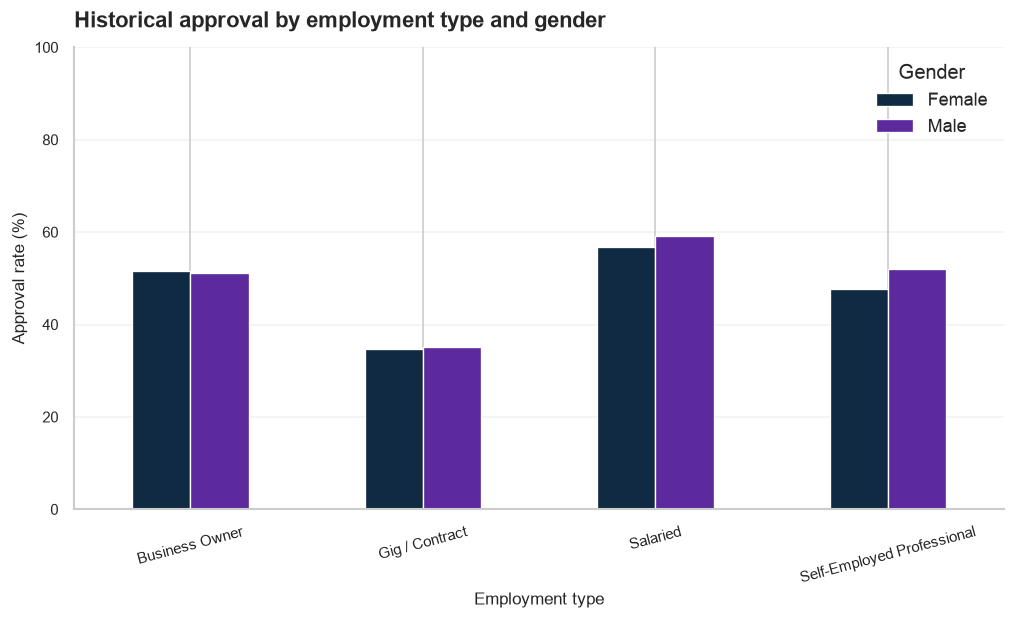

In [23]:
approval_by_employment_gender = (
    df_analysis.pivot_table(
        index="employment_type", columns="gender",
        values="approval_flag", aggfunc="mean"
    ) * 100
)
display(approval_by_employment_gender.style.format("{:.1f}%"))

ax = approval_by_employment_gender.plot(
    kind="bar", figsize=(10, 5), rot=15,
    color=[CHART_APPROVAL_DARK, CHART_ACCENT],
    edgecolor="white", linewidth=0.8
)
format_chart(ax, "Historical approval by employment type and gender", "Employment type", "Approval rate (%)")
ax.set_ylim(0, 100)
ax.legend(title="Gender", frameon=False)
plt.show()

/Users/pratyushkumarpandey/calibo all use cases/calibo use case2/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


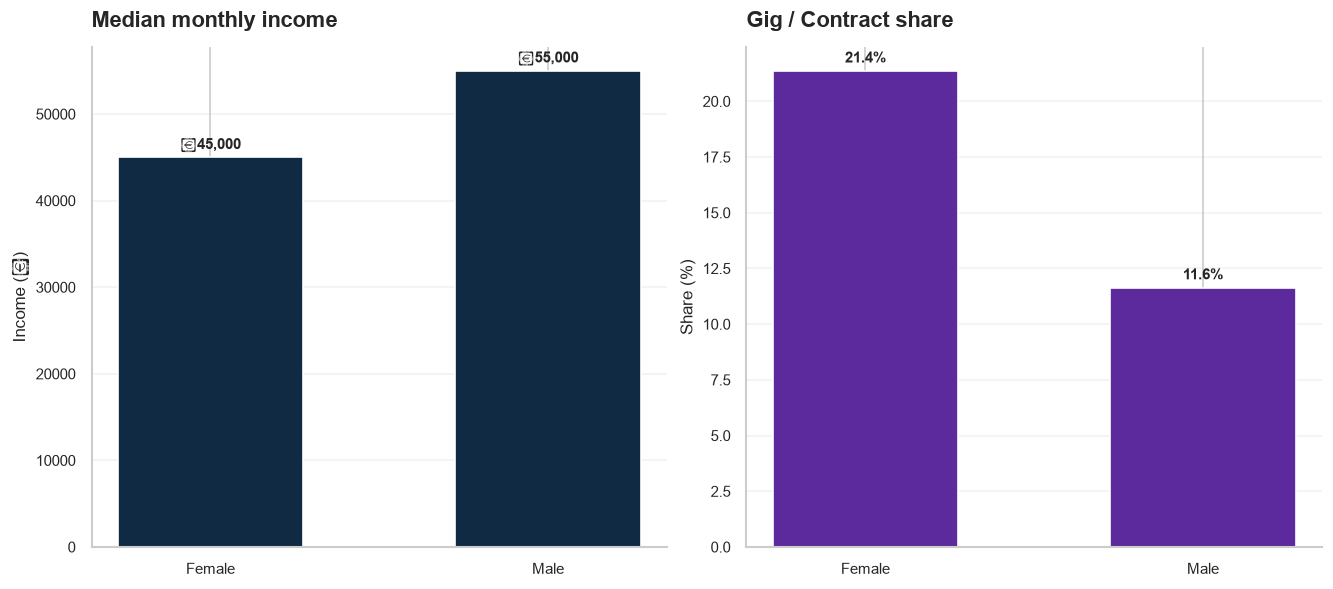

In [24]:
income_gig = gender_summary[["Median_Monthly_Income", "Gig_Contract_Share"]].copy()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)

income_bars = axes[0].bar(income_gig.index, income_gig["Median_Monthly_Income"], color=CHART_APPROVAL_DARK, width=0.55)
for bar in income_bars:
    axes[0].annotate(
        f"₹{bar.get_height():,.0f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5), textcoords="offset points", ha="center", fontsize=9, fontweight="bold"
    )
format_chart(axes[0], "Median monthly income", None, "Income (₹)")

mix_bars = axes[1].bar(income_gig.index, income_gig["Gig_Contract_Share"], color=CHART_ACCENT, width=0.55)
for bar in mix_bars:
    axes[1].annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5), textcoords="offset points", ha="center", fontsize=9, fontweight="bold"
    )
format_chart(axes[1], "Gig / Contract share", None, "Share (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.25)
plt.show()

In [25]:
if chosen_threshold is not None:
    fairness_test = pd.DataFrame({
        "gender": test_raw["gender"].to_numpy(),
        "actual_declined": y_test.to_numpy(),
        "auto_decline": decline_prob >= chosen_threshold
    })
    auto_gender = fairness_test.groupby("gender").agg(
        Test_Applications=("auto_decline", "size"),
        Auto_Declined=("auto_decline", "sum"),
        Auto_Decline_Rate=("auto_decline", "mean")
    )
    auto_gender["Auto_Decline_Rate"] *= 100
    display(auto_gender.style.format({
        "Test_Applications": "{:,.0f}", "Auto_Declined": "{:,.0f}",
        "Auto_Decline_Rate": "{:.2f}%"
    }))

,Test_Applications,Auto_Declined,Auto_Decline_Rate
gender,,,
Female,750,117,15.60%
Male,"1,650",248,15.03%


### What this means

Past approval was about **54.1% for Male applicants and 50.4% for Female applicants**. Female applicants also had lower median income and a higher Gig / Contract share, so income and employment may act as proxy variables. Auto-decline rates were nearly the same at the selected threshold (**15.60% Female versus 15.03% Male**). Leaving gender out is necessary, but monthly monitoring is still needed.

# Step 5.7 — Prepare the Credit Policy Recommendation

<div class="notebook-credit"><strong>Built by:</strong> Pratyush</div>

This section brings the results together for the Credit Policy Analyst. The final briefing below covers the threshold, monthly impact, strongest drivers, human-review group, fairness position and the data still needed before launch.

In [26]:
# Validate the final policy figures from the analysis outputs.
foir_below_30 = foir_summary.loc["Below 30%", "Approval Rate (%)"]
foir_55_plus = foir_summary.loc["Above 55%", "Approval Rate (%)"]
score_below_650 = df_analysis.loc[
    df_analysis["credit_score"].notna() & (df_analysis["credit_score"] < 650),
    "approval_flag"
].mean() * 100

ntc_accuracy = subgroup_accuracy.loc["New to credit", "Accuracy (%)"]
scored_accuracy = subgroup_accuracy.loc["Credit score available", "Accuracy (%)"]
female_approval = gender_summary.loc["Female", "Approval_Rate"]
male_approval = gender_summary.loc["Male", "Approval_Rate"]

if chosen_threshold is not None:
    selected_policy_row = threshold_table.loc[
        threshold_table["Threshold"].eq(chosen_threshold)
    ].iloc[0]
    policy_metrics = pd.DataFrame({
        "Policy measure": [
            "Recommended threshold",
            "Test applications auto-declined (%)",
            "Historically approved in auto-decline lane (%)",
            "Estimated gross monthly applications (before NTC safeguard)",
            "Estimated gross monthly analyst hours (before NTC safeguard)",
            "Recommended monthly applications (after NTC safeguard)",
            "Recommended monthly analyst hours (after NTC safeguard)",
            "New-to-credit test accuracy (%)",
            "Credit-score-available test accuracy (%)",
        ],
        "Value": [
            f"{chosen_threshold:.2f}",
            f"{selected_policy_row['Auto Declined (%)']:.1f}%",
            f"{selected_policy_row['Wrongly Declined (%)']:.1f}%",
            f"{monthly_auto:.0f}",
            f"{monthly_hours:.1f}",
            f"{adjusted_monthly_auto:.0f}",
            f"{adjusted_monthly_hours:.1f}",
            f"{ntc_accuracy:.1f}%",
            f"{scored_accuracy:.1f}%",
        ],
    })
    display(policy_metrics)
    print(
        "Briefing figures checked: threshold, workload, FOIR, score, "
        "new-to-credit reliability and gender outcomes."
    )
else:
    policy_metrics = pd.DataFrame({
        "Policy measure": ["Recommended threshold"],
        "Value": ["None met the 5% wrongful-decline limit"],
    })
    display(policy_metrics)


,Policy measure,Value
0,Recommended threshold,0.90
1,Test applications auto-declined (%),15.2%
2,Historically approved in auto-decline lane (%),4.7%
3,Estimated gross monthly applications (before N...,456
4,Estimated gross monthly analyst hours (before ...,190.1
5,Recommended monthly applications (after NTC sa...,441
6,Recommended monthly analyst hours (after NTC s...,183.9
7,New-to-credit test accuracy (%),56.7%
8,Credit-score-available test accuracy (%),81.2%


Briefing figures checked: threshold, workload, FOIR, score, new-to-credit reliability and gender outcomes.


## Credit Policy Briefing

I recommend auto-declining only when the model is at least **90% confident** that an application will be Declined, and only after keeping new-to-credit applicants with human reviewers. With this safeguard, the policy would remove about **441 applications** and save **183.9 analyst hours** each month. Before the safeguard, the gross estimate was 456 applications and 190.1 hours. The full auto-decline lane meets the safety rule because only **4.7%** were historically approved, and the safeguarded eligible lane has a **3.12%** wrongful-decline rate.

The strongest model signals are FOIR (**+1.220**) and credit score (**−1.010**), followed by recent delinquencies (**+0.979**), Gig / Contract employment (**+0.618**) and Salaried employment (**−0.446**). The historical score pattern is also clear: approval is **2.0% below 600**, **3.2% for 600–649**, and **53.9% for applicants without a score**. Approval falls from **65.5% below 30% FOIR to 15.6% above 55%**. New-to-credit applicants should remain with human reviewers because model accuracy is only **56.7%** for them, compared with **81.2%** for applicants with a score.

Gender is not used directly, but the safeguarded auto-decline rates are still **15.60% for Female applicants versus 15.03% for Male applicants**. Excluding gender does not remove indirect proxy effects from income, employment type and credit history, so outcomes should be checked by gender and employment type every month. Before launch, we need real repayment or default data because this model learns past analyst decisions, not whether customers repaid.

## Final Summary

This notebook checked the data, explained the cleaning choices, studied approval patterns, built affordability features, trained Logistic Regression, tested safe thresholds and reviewed fairness.

**Final caution:** The data is simulated and the target is a past analyst decision. Use the model only as a monitored pre-screening aid, keep new-to-credit applicants with human reviewers and validate it against real repayment outcomes before any live use.

**Team attribution:** Pavitra led data quality and threshold impact; Rachna led approval patterns and fairness; Pratyush led affordability features and the policy story; Pratik led modelling and the peer execution check.